# NB-02 · Stage 3 — DEAN supervised fine-tuning (flat baseline)

**Project:** hierarchical distillation for 12-lead ECG (PTB-XL, 100 Hz)
**Runtime:** Kaggle, GPU T4, internet not required

This notebook takes the self-supervised DEAN encoder from NB-01 and turns it into the flat 26-label classifier that every later tier has to beat. It also freezes DEAN as the teacher and caches everything the distillation notebooks will read from it.

### Input
| Kaggle Dataset | Files used |
|---|---|
| `ptbxl-processed-v1` (Stage 1) | `ptbxl_100hz.npy`, `labels_multihot.csv` |
| `dean-ssl-pretrained-v1` (NB-01) | `dean_lib.py`, `dean_encoder_ssl.pt`, `dean_config.json` |
| *(only when resuming)* `dean-ft-resume` | `dean_ft_last.pt` |

### Output (`/kaggle/working`)
| File | Used by |
|---|---|
| `dean_finetuned.pt` | NB-03 to NB-11 (encoder, head, label order, validation-tuned thresholds, normalisation stats) |
| `baseline_metrics.json`, `val_metrics_table.csv/.tex`, `probe_results.csv` | paper tables, comparison for every later tier |
| `dean_logits_{train,val}.npy`, `dean_emb_{train,val}.npy`, `dean_tokens_{train,val}_fp16.npy`, `split_idx.npz` | NB-03 (gating), NB-04 (prototypes), NB-05 (HOD distillation) |
| `eval_lib.py` | every later notebook (shared metrics and bootstrap code) |
| `ckpt/dean_ft_last.pt` | resume |
| `figures/*.png, *.pdf` | paper figures |

Fold usage: folds 1-8 train, fold 9 validation (model selection and thresholds), **fold 10 is not loaded anywhere in this notebook**. The flat-DEAN test numbers are computed once, in NB-09, with the thresholds saved here.

Order of work: setup, config, artefacts, data, scan check, linear probe, smoke test, fine-tuning, evaluation, figures, export.

## 0. Environment

In [1]:
import os, sys, glob, json, time, math, copy, random, shutil, warnings, platform
from collections import defaultdict
from contextlib import nullcontext

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm.auto import tqdm

warnings.filterwarnings('ignore', category=UserWarning)

ON_KAGGLE = os.path.exists('/kaggle/working')
WORK = '/kaggle/working' if ON_KAGGLE else os.path.abspath('./working')
INPUT_ROOT = os.environ.get('NB_INPUT_ROOT', '/kaggle/input')   # lets us dry-run off Kaggle
os.makedirs(WORK, exist_ok=True)
os.chdir(WORK)
CKPT_DIR = os.path.join(WORK, 'ckpt')
FIG_DIR = os.path.join(WORK, 'figures')
os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if ON_KAGGLE:
    assert dev.type == 'cuda', 'No GPU. Settings -> Accelerator -> GPU T4.'
USE_AMP = dev.type == 'cuda'
if USE_AMP:
    torch.backends.cudnn.benchmark = True

def amp():
    return torch.autocast('cuda', dtype=torch.float16) if USE_AMP else nullcontext()

VERSIONS = {'python': platform.python_version(), 'torch': torch.__version__, 'numpy': np.__version__,
            'pandas': pd.__version__}
print(VERSIONS)
print('device', dev, '|', torch.cuda.get_device_name(0) if USE_AMP else 'cpu', '| work', WORK)

{'python': '3.13.15', 'torch': '2.11.0+cu128', 'numpy': '2.1.3', 'pandas': '2.3.3'}
device cuda | Tesla T4 | work /kaggle/working


## 1. Configuration
Differences from the planning doc, all on purpose:

* **Backbone / head learning rates are 5e-5 / 5e-4**, five times the 1e-5 / 1e-4 in the plan. The SSL encoder only had 25 epochs and a leaky masking task, so at 1e-5 the backbone would barely move in 20 epochs and the result would just be the linear probe again. Both values are one line in `CFG`; if you have the budget, try the plan values as a sweep point.
* **The head is initialised from the linear probe** (section 6), so fine-tuning starts from a sensible classifier instead of random logits wrecking the encoder in the first steps.
* **Model selection uses validation macro-F1 with per-label thresholds tuned on fold 9**, computed over labels with at least 10 validation positives. Labels with fewer positives are too noisy to steer early stopping. They are still reported.
* **All 26 labels are trained in one head** (5 superclass + 21 subclass), because the later tiers need DEAN's 26-d logits as the distillation target.
* Early stopping patience is 6 epochs, the epoch budget is 20. The smoke test prints the real time per epoch before you commit.

In [2]:
CFG = dict(
    seed=42,
    # reliability thresholds on number of positives in the validation fold
    min_pos_select=10, min_pos_report=5,
    # linear probe (cached embeddings, so it is cheap)
    head_drop=0.2, probe_epochs=60, probe_lr=1e-3, probe_wd=1e-2, probe_bs=256,
    # fine-tuning
    epochs=50, batch_size=32, lr_backbone=5e-5, lr_head=5e-4, wd=0.01,
    warmup_epochs=5, lr_floor=0.02, clip=1.0, patience=6,
    grad_ckpt=False,                       # smoke test switches this on by itself if memory runs out
    # loss: sigmoid-F1 + BCE with capped positive weights
    pos_weight_cap=100.0, f1_weight=1.0, bce_weight=1.0, f1_beta=6.0,
    select_metric='f1',                    # 'f1' (plan) or 'auc'
    save_every=2, max_hours=10.5,
    n_boot=300,
)
print({k: CFG[k] for k in ['epochs', 'batch_size', 'lr_backbone', 'lr_head', 'pos_weight_cap', 'select_metric']})

{'epochs': 50, 'batch_size': 32, 'lr_backbone': 5e-05, 'lr_head': 0.0005, 'pos_weight_cap': 100.0, 'select_metric': 'f1'}


## 2. Shared evaluation library
Written to `eval_lib.py` so that NB-03 to NB-11 compute metrics, thresholds and bootstrap intervals with exactly the same code.

In [3]:
%%writefile eval_lib.py
import warnings
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score

warnings.filterwarnings('ignore', category=RuntimeWarning)
THR_GRID = np.round(np.arange(0.02, 0.99, 0.02), 2)


def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))


def auc_per_label(Y, S, min_pos=5):
    out = np.full(Y.shape[1], np.nan)
    n = Y.sum(0)
    for j in range(Y.shape[1]):
        if min_pos <= n[j] < len(Y):
            out[j] = roc_auc_score(Y[:, j], S[:, j])
    return out


def _f1_counts(Y, pred):
    tp = (pred & (Y > 0)).sum(0).astype(float)
    fp = pred.sum(0) - tp
    fn = (Y > 0).sum(0) - tp
    return tp, fp, fn


def f1_at(Y, S, thr):
    # per-label F1 at fixed thresholds; nan where a label has no positives
    tp, fp, fn = _f1_counts(Y, S >= np.asarray(thr)[None])
    den = 2 * tp + fp + fn
    f1 = np.where(den > 0, 2 * tp / np.maximum(den, 1), 0.0)
    f1[(Y > 0).sum(0) == 0] = np.nan
    return f1


def tune_thresholds(Y, S, grid=THR_GRID):
    # one threshold per label, picked on the data given (call this on validation only)
    pred = S[:, :, None] >= grid[None, None, :]
    pos = Y[:, :, None] > 0
    tp = (pred & pos).sum(0).astype(float)
    fp = pred.sum(0) - tp
    fn = pos.sum(0) - tp
    den = 2 * tp + fp + fn
    f1 = np.where(den > 0, 2 * tp / np.maximum(den, 1), 0.0)
    best = f1.argmax(1)
    thr = grid[best].copy()
    f1b = f1[np.arange(len(best)), best]
    nopos = (Y > 0).sum(0) == 0
    thr[nopos] = 0.5
    f1b[nopos] = np.nan
    return thr, f1b


def summarize(Y, S, min_pos):
    # macro AUC and macro F1 (val-tuned thresholds) over labels with >= min_pos positives
    thr, f1 = tune_thresholds(Y, S)
    auc = auc_per_label(Y, S, min_pos)
    mask = Y.sum(0) >= min_pos
    m_auc = float(np.nanmean(auc[mask])) if mask.any() else float('nan')
    m_f1 = float(np.nanmean(f1[mask])) if mask.any() else float('nan')
    return dict(macro_auc=m_auc, macro_f1=m_f1), thr, auc, f1


def bootstrap(Y, S, thr, min_pos=5, n_boot=300, seed=0, n_super=5):
    # resample records; thresholds stay fixed (they are not re-tuned per resample)
    rng = np.random.default_rng(seed)
    N, L = Y.shape
    aucs = np.full((n_boot, L), np.nan)
    f1s = np.full((n_boot, L), np.nan)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        aucs[b] = auc_per_label(Y[idx], S[idx], 1)
        f1s[b] = f1_at(Y[idx], S[idx], thr)
    mask = Y.sum(0) >= min_pos
    sup = mask.copy(); sup[n_super:] = False
    sub = mask.copy(); sub[:n_super] = False

    def ci(v):
        return [float(np.nanmean(v)), float(np.nanpercentile(v, 2.5)), float(np.nanpercentile(v, 97.5))]
    out = {'macro_auc': ci(np.nanmean(aucs[:, mask], 1)), 'macro_f1': ci(np.nanmean(f1s[:, mask], 1))}
    if sup.any(): out['super_auc'] = ci(np.nanmean(aucs[:, sup], 1))
    if sub.any(): out['sub_auc'] = ci(np.nanmean(aucs[:, sub], 1))
    out['label_auc_lo'] = np.nanpercentile(aucs, 2.5, axis=0)
    out['label_auc_hi'] = np.nanpercentile(aucs, 97.5, axis=0)
    return out


def per_label_table(names, Y, S, thr, min_pos=5):
    auc = auc_per_label(Y, S, 1)
    f1 = f1_at(Y, S, thr)
    pred = S >= np.asarray(thr)[None]
    tp, fp, fn = _f1_counts(Y, pred)
    rows = []
    for j, n in enumerate(names):
        npos = int(Y[:, j].sum())
        ap = average_precision_score(Y[:, j], S[:, j]) if 0 < npos < len(Y) else np.nan
        rows.append(dict(label=n, n_pos=npos, auc=auc[j], ap=ap, f1=f1[j], threshold=float(thr[j]),
                         precision=tp[j] / max(tp[j] + fp[j], 1), recall=tp[j] / max(tp[j] + fn[j], 1),
                         reliable=bool(npos >= min_pos)))
    return pd.DataFrame(rows)


def reliability(y, p, bins=10):
    # equal-mass bins, returns (mean confidence, observed frequency, ECE)
    order = np.argsort(p)
    chunks = np.array_split(order, bins)
    conf = np.array([p[c].mean() for c in chunks])
    acc = np.array([y[c].mean() for c in chunks])
    w = np.array([len(c) for c in chunks]) / len(p)
    return conf, acc, float((w * np.abs(conf - acc)).sum())

Writing eval_lib.py


In [4]:
import importlib
sys.path.insert(0, WORK)
import eval_lib
importlib.reload(eval_lib)
from eval_lib import (sigmoid, auc_per_label, f1_at, tune_thresholds, summarize, bootstrap,
                      per_label_table, reliability)

import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'font.family': 'serif', 'font.size': 9,
    'axes.titlesize': 10, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'legend.frameon': False, 'pdf.fonttype': 42,
})
SUPER = ['NORM', 'MI', 'STTC', 'CD', 'HYP']
SUPER_COL = {'NORM': '#009E73', 'MI': '#D55E00', 'STTC': '#0072B2', 'CD': '#CC79A7', 'HYP': '#E69F00'}
LEADS = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
FAMILY = {  # subclass -> parent superclass (NORM and STTC parents are their own columns)
    'AMI': 'MI', 'IMI': 'MI', 'LMI': 'MI', 'PMI': 'MI',
    'ISCA': 'STTC', 'ISCI': 'STTC', 'ISC_': 'STTC', 'NST_': 'STTC',
    'CLBBB': 'CD', 'CRBBB': 'CD', 'ILBBB': 'CD', 'IRBBB': 'CD', 'IVCD': 'CD', 'LAFB/LPFB': 'CD', 'WPW': 'CD', '_AVB': 'CD',
    'LAO/LAE': 'HYP', 'LVH': 'HYP', 'RAO/RAE': 'HYP', 'RVH': 'HYP', 'SEHYP': 'HYP'}

def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name + '.png'), bbox_inches='tight')
    fig.savefig(os.path.join(FIG_DIR, name + '.pdf'), bbox_inches='tight')
    plt.show()

## 3. NB-01 artefacts
Finds `dean_lib.py` and the SSL weights in the attached Datasets, and reads the encoder configuration, the normalisation statistics and the label order from them. Nothing about the architecture is typed in again here, so a better SSL encoder from a later run drops in without edits.

In [5]:
def find_one(name):
    hits = sorted(glob.glob(f'{INPUT_ROOT}/**/{name}', recursive=True)) + sorted(glob.glob(f'./**/{name}', recursive=True))
    if not hits:
        raise FileNotFoundError(f'{name} not found. Attach the Dataset that contains it.')
    return hits[0]

lib_src = find_one('dean_lib.py')
if os.path.abspath(lib_src) != os.path.join(WORK, 'dean_lib.py'):
    shutil.copy(lib_src, os.path.join(WORK, 'dean_lib.py'))
import dean_lib
importlib.reload(dean_lib)
from dean_lib import DEANEncoder, count_params, light_aug, embed_all
print('dean_lib from', lib_src, '| cuda mamba kernels:', dean_lib.USE_CUDA_MAMBA)

ssl_path = find_one('dean_encoder_ssl.pt')
ssl_ckpt = torch.load(ssl_path, map_location='cpu', weights_only=False)
ENC_CFG = ssl_ckpt['enc_config']
SSL_KEY = ssl_ckpt['recommended']
MU = np.array(ssl_ckpt['norm_mean'], dtype=np.float32)
SD = np.array(ssl_ckpt['norm_std'], dtype=np.float32)
print('ssl weights:', ssl_path, '| key', SSL_KEY, '| epochs', ssl_ckpt['epochs_done'])
print('encoder config:', ENC_CFG)

try:
    LABELS = json.load(open(find_one('dean_config.json')))['label_columns']
except Exception as e:
    print('dean_config.json label list not usable, falling back to csv order:', e)
    LABELS = None

def build_encoder(grad_ckpt=None):
    c = dict(ENC_CFG)
    if grad_ckpt is not None:
        c['grad_ckpt'] = grad_ckpt
    return DEANEncoder(**c)

D_MODEL = ENC_CFG['d_model']

dean_lib from /kaggle/input/datasets/iaadidev/results-stage-2-hidmamba/dean_lib.py | cuda mamba kernels: False
ssl weights: /kaggle/input/datasets/iaadidev/results-stage-2-hidmamba/dean_encoder_ssl.pt | key encoder | epochs 25
encoder config: {'in_ch': 12, 'seq_len': 1000, 'patch': 25, 'd_model': 256, 'depth': 10, 'd_state': 16, 'd_conv': 4, 'expand': 2, 'dropout': 0.1, 'ffn_mult': 2, 'grad_ckpt': True}


## 4. Data
Same arrays and the same per-lead standardisation as NB-01 (statistics come from the SSL checkpoint, not recomputed). Only folds 1-8 and 9 are read into memory.

In [6]:
sig_path = find_one('ptbxl_100hz.npy')
lab_path = find_one('labels_multihot.csv')
sig = np.load(sig_path, mmap_mode='r')
if sig.ndim == 3 and sig.shape[1] != 12 and sig.shape[2] == 12:
    sig = np.transpose(sig, (0, 2, 1))
df = pd.read_csv(lab_path)
df = df.loc[:, ~df.columns.str.startswith('Unnamed')]
assert len(df) == sig.shape[0], f'row mismatch: csv {len(df)} vs npy {sig.shape[0]}'

fold_col = next(c for c in ('strat_fold', 'fold') if c in df.columns)
if LABELS is None:
    LABELS = SUPER + [c for c in df.columns if c not in set(SUPER) | {fold_col, 'ecg_id', 'patient_id'}]
assert LABELS[:5] == SUPER and all(c in df.columns for c in LABELS), 'label columns do not match the csv'
SUB = LABELS[5:]
print(f'{len(SUPER)} super + {len(SUB)} sub = {len(LABELS)} labels | fold column: {fold_col}')

fold = df[fold_col].values.astype(int)
tr_idx = np.where(fold <= 8)[0]
va_idx = np.where(fold == 9)[0]
te_idx = np.where(fold == 10)[0]            # indices only, the signals are never read here
ecg_id = df['ecg_id'].values if 'ecg_id' in df.columns else np.arange(len(df))
print('train', len(tr_idx), '| val', len(va_idx), '| fold 10 records (not loaded):', len(te_idx))

def load_std(idx):
    x = np.ascontiguousarray(sig[idx]).astype(np.float32)
    x = np.nan_to_num(x)
    return (x - MU[None, :, None]) / SD[None, :, None]

Yall = df[LABELS].values.astype(np.float32)
DATA = dict(
    X_tr=torch.from_numpy(load_std(tr_idx)).to(dev), X_va=torch.from_numpy(load_std(va_idx)).to(dev),
    Y_tr=torch.from_numpy(Yall[tr_idx]).to(dev), Y_va=Yall[va_idx],
)
print('train tensor', tuple(DATA['X_tr'].shape), '| val tensor', tuple(DATA['X_va'].shape),
      f"| gpu memory {torch.cuda.memory_allocated()/1e9:.2f} GB" if USE_AMP else '')

# positive-class weights, capped (a 1900x weight on 13 PMI records would just destabilise training)
n_pos_tr = Yall[tr_idx].sum(0)
POS_W = torch.tensor(np.clip((len(tr_idx) - n_pos_tr) / np.maximum(n_pos_tr, 1), 1.0, CFG['pos_weight_cap']),
                     dtype=torch.float32, device=dev)
n_pos_va = DATA['Y_va'].sum(0)
tab = pd.DataFrame({'train_pos': n_pos_tr.astype(int), 'val_pos': n_pos_va.astype(int),
                    'pos_weight': POS_W.cpu().numpy().round(1)}, index=LABELS)
print(tab.T.to_string())
print('labels with < min_pos_select validation positives:', [l for l, n in zip(LABELS, n_pos_va) if n < CFG['min_pos_select']])

5 super + 21 sub = 26 labels | fold column: strat_fold
train 17418 | val 2183 | fold 10 records (not loaded): 2198
train tensor (17418, 12, 1000) | val tensor (2183, 12, 1000) | gpu memory 0.94 GB
              NORM      MI    STTC      CD     HYP     AMI     IMI    LMI    PMI        ISCA   ISCI         ISC_        NST_       CLBBB       CRBBB  ILBBB  IRBBB   IVCD  LAFB/LPFB    WPW   _AVB     LAO/LAE     LVH  RAO/RAE    RVH  SEHYP
train_pos   7542.0  3307.0  4062.0  3900.0  1820.0  2054.0  1791.0  100.0    9.0  750.000000  314.0  1008.000000  449.000000  428.000000  431.000000   61.0  891.0  630.0     1437.0   64.0  655.0  334.000000  1411.0     79.0   92.0   24.0
val_pos      942.0   412.0   510.0   495.0   216.0   258.0   227.0   12.0    2.0   91.000000   37.0   124.000000   56.000000   54.000000   55.000000    7.0  112.0   78.0      180.0    7.0   83.0   40.000000   163.0     10.0    9.0    3.0
pos_weight     1.3     4.3     3.3     3.5     8.6     7.5     8.7  100.0  100.0   22.200

## 5. Model, loss and the Mamba scan
The head standardises the pooled embedding with train-set statistics (the SSL embeddings are not centred, see the NB-01 review) and then applies dropout and a linear layer.

The loss is a differentiable F1 surrogate (sigmoid-F1, evaluated over the labels that actually have a positive in the batch) plus class-weighted BCE. The F1 term is noisy at batch 32 for rare labels, which is why the BCE term stays in. `f1_weight=0` gives the BCE-only variant for the ablation.

**Scan benchmark.** The pure-PyTorch scan in `dean_lib.py` indexes `dA[:, t]` inside the loop, which makes autograd build full-size gradient tensors at every step. The alternative below never builds the (B, L, D, N) tensors. The cell checks that both give the same output and gradients on the GPU and uses the faster one for this notebook.

In [7]:
class Head(nn.Module):
    def __init__(self, mu, sd, n_out, drop):
        super().__init__()
        self.register_buffer('mu', torch.as_tensor(mu, dtype=torch.float32).clone())
        self.register_buffer('sd', torch.as_tensor(sd, dtype=torch.float32).clone())
        self.drop = nn.Dropout(drop)
        self.fc = nn.Linear(len(self.mu), n_out)

    def forward(self, z):
        return self.fc(self.drop((z.float() - self.mu) / self.sd))


class FTModel(nn.Module):
    def __init__(self, enc, head):
        super().__init__()
        self.enc, self.head = enc, head

    def forward(self, x):
        return self.head(self.enc(x).float().mean(1))


def sigmoid_f1_loss(logits, y, beta):
    p = torch.sigmoid(logits.float())
    ps = torch.sigmoid(beta * (p - 0.5))              # steepened, so it behaves like a threshold at 0.5
    tp, fp, fn = (ps * y).sum(0), (ps * (1 - y)).sum(0), ((1 - ps) * y).sum(0)
    f1 = 2 * tp / (2 * tp + fp + fn + 1e-6)
    has = y.sum(0) > 0
    return 1 - f1[has].mean() if has.any() else logits.sum() * 0.0


def ft_loss(logits, y, cfg):
    bce = F.binary_cross_entropy_with_logits(logits.float(), y, pos_weight=POS_W)
    f1l = sigmoid_f1_loss(logits, y, cfg['f1_beta']) if cfg['f1_weight'] > 0 else logits.sum() * 0.0
    return cfg['f1_weight'] * f1l + cfg['bce_weight'] * bce, bce.detach(), f1l.detach()


def fast_scan(u, dt, A, Bm, Cm, D):
    # same maths as dean_lib.selective_scan, written so no (B,L,Din,N) tensor is ever built
    with torch.autocast(device_type='cuda', enabled=False):
        u, dt, Bm, Cm = u.float(), dt.float(), Bm.float(), Cm.float()
        h = torch.zeros(u.shape[0], u.shape[2], A.shape[1], device=u.device)
        ys = []
        for u_t, dt_t, B_t, C_t in zip(u.unbind(1), dt.unbind(1), Bm.unbind(1), Cm.unbind(1)):
            h = torch.exp(dt_t.unsqueeze(-1) * A) * h + (dt_t * u_t).unsqueeze(-1) * B_t.unsqueeze(1)
            ys.append(torch.einsum('bdn,bn->bd', h, C_t))
        return torch.stack(ys, 1) + u * D


def bench_scan(n=10):
    if dean_lib.USE_CUDA_MAMBA:
        print('CUDA mamba kernels are active, scan benchmark skipped')
        return
    B, L, Din, N = CFG['batch_size'], ENC_CFG['seq_len'] // ENC_CFG['patch'], ENC_CFG['expand'] * D_MODEL, ENC_CFG['d_state']
    g = torch.Generator().manual_seed(0)
    mk = lambda *s: torch.randn(*s, generator=g).to(dev).requires_grad_()
    u, Bm, Cm = mk(B, L, Din), mk(B, L, N), mk(B, L, N)
    dt = (torch.rand(B, L, Din, generator=g) * 0.5).to(dev).requires_grad_()
    A = (-(torch.rand(Din, N, generator=g) + 1)).to(dev).requires_grad_()
    Dp = torch.ones(Din, device=dev)
    res = {}
    for name, fn in [('library scan', dean_lib.selective_scan), ('unbind scan', fast_scan)]:
        for _ in range(2):
            fn(u, dt, A, Bm, Cm, Dp).sum().backward()
        if USE_AMP: torch.cuda.synchronize()
        t = time.time()
        for _ in range(n):
            for p in (u, dt, A, Bm, Cm): p.grad = None
            y = fn(u, dt, A, Bm, Cm, Dp)
            y.sum().backward()
        if USE_AMP: torch.cuda.synchronize()
        res[name] = ((time.time() - t) / n * 1000, y.detach().clone(), [p.grad.clone() for p in (u, dt, A, Bm, Cm)])
    same = torch.allclose(res['library scan'][1], res['unbind scan'][1], atol=1e-3, rtol=1e-3) and all(
        torch.allclose(a, b, atol=1e-2, rtol=1e-2) for a, b in zip(res['library scan'][2], res['unbind scan'][2]))
    t_lib, t_new = res['library scan'][0], res['unbind scan'][0]
    print(f'per scan fwd+bwd at batch {B}: library {t_lib:.1f} ms | unbind {t_new:.1f} ms | outputs and gradients match: {same}')
    if same and t_new < 0.9 * t_lib:
        dean_lib.selective_scan = fast_scan
        print(f'using the unbind scan ({t_lib / t_new:.1f}x faster)')
    else:
        print('keeping the library scan')

bench_scan()

_m = FTModel(build_encoder(False), Head(np.zeros(D_MODEL), np.ones(D_MODEL), len(LABELS), CFG['head_drop']))
print(f'encoder {count_params(_m.enc)/1e6:.2f} M | head {count_params(_m.head)/1e3:.1f} K parameters')
del _m

per scan fwd+bwd at batch 32: library 67.5 ms | unbind 23.4 ms | outputs and gradients match: True
using the unbind scan (2.9x faster)
encoder 11.48 M | head 6.7 K parameters


## 6. Helpers: inference, linear probe, fine-tuning loop
`run_finetune` is the same function for the smoke test and the real run. It keeps the best epoch (by the selection metric) inside the checkpoint, so a resumed run still returns the right weights.

In [8]:
@torch.no_grad()
def predict(model, X, bs=256, tokens=False):
    # returns logits (N,L) and pooled embeddings (N,D), plus fp16 token sequences (N,T,D) on request
    was = model.training
    model.eval()
    lg, em, tk = [], [], []
    for i in range(0, len(X), bs):
        with amp():
            tok = model.enc(X[i:i + bs])
            z = tok.float().mean(1)
            out = model.head(z)
        lg.append(out.float().cpu()); em.append(z.cpu())
        if tokens:
            tk.append(tok.half().cpu())
    model.train(was)
    res = [torch.cat(lg).numpy(), torch.cat(em).numpy()]
    if tokens:
        res.append(torch.cat(tk).numpy())
    return res


def head_from(Z):
    mu, sd = Z.mean(0), Z.std(0) + 1e-6
    head = Head(mu, sd, len(LABELS), CFG['head_drop']).to(dev)
    p = np.clip(DATA['Y_tr'].mean(0).cpu().numpy(), 1e-4, 1 - 1e-4)
    with torch.no_grad():
        head.fc.bias.copy_(torch.tensor(np.log(p / (1 - p)), dtype=torch.float32))
    return head


def train_probe(Ztr, Ytr, Zva, Yva, cfg, seed=0):
    # linear head on frozen, cached embeddings; keeps the epoch with the best validation macro-AUC
    torch.manual_seed(seed)
    head = head_from(Ztr)
    opt = torch.optim.AdamW(head.parameters(), lr=cfg['probe_lr'], weight_decay=cfg['probe_wd'])
    n, bs = len(Ztr), cfg['probe_bs']
    spe = math.ceil(n / bs)
    total = cfg['probe_epochs'] * spe
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: 0.5 * (1 + math.cos(math.pi * min(1.0, s / total))))
    best, best_state, best_S, hist = -1.0, None, None, []
    for ep in range(cfg['probe_epochs']):
        head.train()
        perm = torch.randperm(n, device=Ztr.device)
        tot = 0.0
        for i in range(spe):
            idx = perm[i * bs:(i + 1) * bs]
            loss, _, _ = ft_loss(head(Ztr[idx]), Ytr[idx], cfg)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step(); sched.step()
            tot += float(loss)
        if (ep + 1) % 5 == 0 or ep + 1 == cfg['probe_epochs']:
            head.eval()
            with torch.no_grad():
                S = torch.sigmoid(head(Zva)).cpu().numpy()
            auc = float(np.nanmean(auc_per_label(Yva, S, cfg['min_pos_select'])[Yva.sum(0) >= cfg['min_pos_select']]))
            hist.append((ep + 1, tot / spe, auc))
            if auc > best:
                best, best_S = auc, S
                best_state = {k: v.detach().clone() for k, v in head.state_dict().items()}
    return best_state, best_S, best, hist


def cosine_scale(step, total, warm, floor):
    if step < warm:
        return (step + 1) / warm
    p = min(1.0, (step - warm) / max(1, total - warm))
    return floor + (1 - floor) * 0.5 * (1 + math.cos(math.pi * p))


def run_finetune(cfg, data, out_dir, enc_state, head_state, resume_path=None, tag='ft'):
    os.makedirs(out_dir, exist_ok=True)
    torch.manual_seed(cfg['seed']); np.random.seed(cfg['seed']); random.seed(cfg['seed'])
    enc = build_encoder(cfg['grad_ckpt'])
    enc.load_state_dict(enc_state)
    head = Head(torch.zeros(D_MODEL), torch.ones(D_MODEL), len(LABELS), cfg['head_drop'])
    head.load_state_dict(head_state)
    model = FTModel(enc, head).to(dev)

    def groups(module, lr):
        dec, nod = [], []
        for n, p in module.named_parameters():
            (nod if (p.ndim < 2 or 'pos_emb' in n) else dec).append(p)
        return [{'params': dec, 'weight_decay': cfg['wd'], 'base': lr},
                {'params': nod, 'weight_decay': 0.0, 'base': lr}]
    opt = torch.optim.AdamW(groups(model.enc, cfg['lr_backbone']) + groups(model.head, cfg['lr_head']))
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)

    X, Y = data['X_tr'], data['Y_tr']
    N, bs = len(X), cfg['batch_size']
    spe = math.ceil(N / bs)
    total, warm = cfg['epochs'] * spe, cfg['warmup_epochs'] * spe
    start, step, history, best_score, best_epoch, best_state, bad = 0, 0, [], -1.0, 0, None, 0
    if resume_path and os.path.exists(resume_path):
        s = torch.load(resume_path, map_location='cpu', weights_only=False)
        model.load_state_dict(s['model']); opt.load_state_dict(s['opt']); scaler.load_state_dict(s['scaler'])
        start, step, history = s['epoch'], s['step'], s['history']
        best_score, best_epoch, best_state, bad = s['best_score'], s['best_epoch'], s['best_state'], s['bad']
        print(f'[{tag}] resumed from {resume_path}: epoch {start}, best epoch {best_epoch} ({best_score:.4f})')

    ckpt_path = os.path.join(out_dir, 'dean_ft_last.pt')
    t_start, stopped_early = time.time(), False
    if USE_AMP: torch.cuda.reset_peak_memory_stats()

    for epoch in range(start, cfg['epochs']):
        model.train()
        t_ep = time.time()
        gen = torch.Generator().manual_seed(cfg['seed'] * 1000 + epoch)
        perm = torch.randperm(N, generator=gen).to(dev)
        acc = defaultdict(float)
        bar = tqdm(range(spe), desc=f'[{tag}] epoch {epoch + 1}/{cfg["epochs"]}', leave=False)
        for i in bar:
            idx = perm[i * bs:(i + 1) * bs]
            x, y = light_aug(X[idx]), Y[idx]
            sc = cosine_scale(step, total, warm, cfg['lr_floor'])
            for g in opt.param_groups:
                g['lr'] = g['base'] * sc
            with amp():
                logits = model(x)
            loss, bce, f1l = ft_loss(logits, y, cfg)
            if not torch.isfinite(loss):
                raise RuntimeError('non-finite loss, check the data and lower the learning rates')
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg['clip'])
            scaler.step(opt); scaler.update()
            step += 1
            acc['loss'] += float(loss); acc['bce'] += float(bce); acc['f1_loss'] += float(f1l)
            if i % 20 == 0:
                bar.set_postfix(loss=f'{acc["loss"] / (i + 1):.3f}')
        bar.close()
        if USE_AMP: torch.cuda.synchronize()
        ep_time = time.time() - t_ep

        logits_va, _ = predict(model, data['X_va'])
        S = sigmoid(logits_va)
        summ, _, _, _ = summarize(data['Y_va'], S, cfg['min_pos_select'])
        score = summ['macro_f1'] if cfg['select_metric'] == 'f1' else summ['macro_auc']
        score = -1.0 if not np.isfinite(score) else score
        done = epoch + 1
        row = {'epoch': done, 'step': step, 'lr_backbone': cfg['lr_backbone'] * sc, 'lr_head': cfg['lr_head'] * sc,
               'sec_per_epoch': ep_time, 'sec_per_step': ep_time / spe,
               'gpu_peak_gb': torch.cuda.max_memory_allocated() / 1e9 if USE_AMP else 0.0,
               'val_macro_auc': summ['macro_auc'], 'val_macro_f1': summ['macro_f1']}
        row.update({k: v / spe for k, v in acc.items()})
        history.append(row)
        improved = score > best_score
        if improved:
            best_score, best_epoch, bad = score, done, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        elapsed_h = (time.time() - t_start) / 3600
        stop_now = bool(cfg['max_hours']) and done < cfg['epochs'] and elapsed_h + 1.5 * (time.time() - t_ep) / 3600 > cfg['max_hours']
        if done % cfg['save_every'] == 0 or done == cfg['epochs'] or stop_now or bad >= cfg['patience']:
            torch.save({'model': model.state_dict(), 'opt': opt.state_dict(), 'scaler': scaler.state_dict(),
                        'epoch': done, 'step': step, 'history': history, 'best_score': best_score,
                        'best_epoch': best_epoch, 'best_state': best_state, 'bad': bad, 'cfg': cfg},
                       ckpt_path + '.tmp')
            os.replace(ckpt_path + '.tmp', ckpt_path)
        print(f"[{tag}] ep {done:2d} | loss {row['loss']:.4f} (bce {row['bce']:.4f}, f1 {row['f1_loss']:.3f}) | "
              f"val AUC {summ['macro_auc']:.4f} F1 {summ['macro_f1']:.4f} | {ep_time:5.0f}s{' | best' if improved else ''}")
        if bad >= cfg['patience']:
            print(f'[{tag}] no improvement for {cfg["patience"]} epochs, stopping at epoch {done}')
            break
        if stop_now:
            stopped_early = True
            print(f'[{tag}] time budget reached after epoch {done}. State saved, re-run to resume.')
            break

    model.load_state_dict(best_state)
    return dict(model=model, history=history, best_epoch=best_epoch, best_score=best_score,
                stopped_early=stopped_early, steps_per_epoch=spe)

## 7. Smoke test
Runs the real code on a small slice: probe training, two fine-tuning epochs, a checkpoint round trip and a resume. It then prints peak memory and the real time per step with a projection for the full run. If the first attempt runs out of memory without gradient checkpointing, it retries with checkpointing and records that in `CFG`.

In [9]:
def smoke_test(cfg, data):
    print('=' * 70, '\nSMOKE TEST\n' + '=' * 70)
    c = dict(cfg)
    c.update(epochs=2, warmup_epochs=1, patience=99, save_every=1, max_hours=0, min_pos_select=2, min_pos_report=2, probe_epochs=5)
    nsm, nva = 8 * c['batch_size'], min(300, len(data['X_va']))
    small = dict(X_tr=data['X_tr'][:nsm], Y_tr=data['Y_tr'][:nsm], X_va=data['X_va'][:nva], Y_va=data['Y_va'][:nva])
    tmp = os.path.join(WORK, 'smoke_tmp')
    shutil.rmtree(tmp, ignore_errors=True)
    enc_state = ssl_ckpt[SSL_KEY]

    # probe path
    enc0 = build_encoder(False).to(dev)
    enc0.load_state_dict(enc_state)
    Ztr, Zva = embed_all(enc0, small['X_tr'], amp=USE_AMP), embed_all(enc0, small['X_va'], amp=USE_AMP)
    assert Ztr.shape == (nsm, D_MODEL) and torch.isfinite(Ztr).all(), 'embeddings are not finite'
    hs, S, auc, _ = train_probe(Ztr, small['Y_tr'], Zva, small['Y_va'], c)
    assert S.shape == (nva, len(LABELS)) and np.isfinite(S).all()
    print(f'[ok] embeddings {tuple(Ztr.shape)}, probe trains, val scores finite (tiny-slice AUC {auc:.3f})')
    del enc0

    # fine-tuning, with a retry on out-of-memory
    r1 = None
    for gc in (c['grad_ckpt'], True):
        c['grad_ckpt'] = gc
        try:
            r1 = run_finetune(c, small, tmp, enc_state, hs, tag='smoke')
            break
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache(); shutil.rmtree(tmp, ignore_errors=True)
            print('     out of memory without gradient checkpointing, retrying with it')
    assert r1 is not None, 'out of memory even with checkpointing, lower batch_size'
    CFG['grad_ckpt'] = c['grad_ckpt']
    assert len(r1['history']) == 2 and all(np.isfinite(h['loss']) for h in r1['history'])
    m = r1['model']
    assert not torch.equal(m.enc.patch_embed.weight.cpu(), enc_state['patch_embed.weight']), 'encoder did not move'
    assert torch.equal(m.head.mu.cpu(), hs['mu'].cpu()), 'head standardisation must stay fixed'
    print('[ok] finite loss, encoder updates, head statistics fixed')

    ck = os.path.join(tmp, 'dean_ft_last.pt')
    c3 = dict(c); c3['epochs'] = 3
    r2 = run_finetune(c3, small, tmp, enc_state, hs, resume_path=ck, tag='smoke-resume')
    assert len(r2['history']) == 3 and r2['history'][-1]['step'] == 3 * r1['steps_per_epoch'], 'resume did not continue the step counter'
    print('[ok] checkpoint save and resume')

    sps = r2['history'][-1]['sec_per_step']
    spe_full = math.ceil(len(data['X_tr']) / cfg['batch_size'])
    t = time.time(); predict(r2['model'], data['X_va'][:256]); t_eval = (time.time() - t) / 256 * len(data['X_va'])
    peak = r2['history'][-1]['gpu_peak_gb']
    total_h = (sps * spe_full + t_eval) * cfg['epochs'] / 3600
    print(f'[ok] peak GPU memory {peak:.1f} GB' + (f' of {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB' if USE_AMP else ''))
    print(f'     {sps:.2f} s/step at batch {cfg["batch_size"]} -> {sps*spe_full/60:.1f} min/epoch (+{t_eval:.0f}s validation), '
          f'~{total_h:.1f} h for {cfg["epochs"]} epochs, less if early stopping fires')
    print(f'     gradient checkpointing for the real run: {CFG["grad_ckpt"]}')
    if total_h > cfg['max_hours']:
        print('     note: this exceeds max_hours, the run will pause and resume in a second session.')
    shutil.rmtree(tmp, ignore_errors=True)
    print('SMOKE TEST PASSED')
    return True

RUN_SMOKE = True            # False when resuming in a later session
SMOKE_OK = smoke_test(CFG, DATA) if RUN_SMOKE else True

SMOKE TEST
[ok] embeddings (256, 256), probe trains, val scores finite (tiny-slice AUC 0.629)


[smoke] epoch 1/2:   0%|          | 0/8 [00:00<?, ?it/s]

[smoke] ep  1 | loss 2.0170 (bce 1.1642, f1 0.853) | val AUC 0.6798 F1 0.2778 |     6s | best


[smoke] epoch 2/2:   0%|          | 0/8 [00:00<?, ?it/s]

[smoke] ep  2 | loss 1.4886 (bce 0.7102, f1 0.778) | val AUC 0.7020 F1 0.3097 |     4s | best
[ok] finite loss, encoder updates, head statistics fixed
[smoke-resume] resumed from /kaggle/working/smoke_tmp/dean_ft_last.pt: epoch 2, best epoch 2 (0.3097)


[smoke-resume] epoch 3/3:   0%|          | 0/8 [00:00<?, ?it/s]

[smoke-resume] ep  3 | loss 1.3551 (bce 0.6111, f1 0.744) | val AUC 0.7166 F1 0.3270 |     4s | best
[ok] checkpoint save and resume
[ok] peak GPU memory 3.5 GB of 15.6 GB
     0.54 s/step at batch 32 -> 4.9 min/epoch (+4s validation), ~4.2 h for 50 epochs, less if early stopping fires
     gradient checkpointing for the real run: False
SMOKE TEST PASSED


## 8. Linear probe: how good is the SSL encoder on its own?
Frozen encoder, embeddings computed once, a linear head trained on top. A randomly initialised encoder of the same architecture is probed the same way, which is the honest reference for what NB-01 contributed. The kNN numbers from NB-01 understated the encoder because the embeddings are not centred; this probe fixes that.

In [10]:
assert SMOKE_OK, 'run the smoke test first'
Ytr_t, Yva = DATA['Y_tr'], DATA['Y_va']

enc_ssl = build_encoder(False).to(dev)
enc_ssl.load_state_dict(ssl_ckpt[SSL_KEY])
torch.manual_seed(0)
enc_rand = build_encoder(False).to(dev)

t0 = time.time()
Z = {nm: (embed_all(e, DATA['X_tr'], amp=USE_AMP), embed_all(e, DATA['X_va'], amp=USE_AMP))
     for nm, e in [('random init', enc_rand), ('DEAN-SSL', enc_ssl)]}
print(f'embeddings computed in {time.time() - t0:.0f}s')

PROBE = {}
for nm, (ztr, zva) in Z.items():
    hs, S, auc, hist = train_probe(ztr, Ytr_t, zva, Yva, CFG)
    PROBE[nm] = dict(head=hs, S=S)
    print(f'{nm:12s} probe: best val macro-AUC (labels with >= {CFG["min_pos_select"]} positives) {auc:.4f}')

def auc_row(S, min_pos):
    a = auc_per_label(Yva, S, min_pos)
    n = Yva.sum(0)
    ok = n >= min_pos
    return dict(super_auc=float(np.nanmean(a[:5][ok[:5]])), sub_auc=float(np.nanmean(a[5:][ok[5:]])),
                all_auc=float(np.nanmean(a[ok])))

probe_tab = pd.DataFrame({nm: auc_row(v['S'], CFG['min_pos_report']) for nm, v in PROBE.items()}).T
print(probe_tab.round(4))
probe_tab.to_csv(os.path.join(WORK, 'probe_results.csv'))
torch.save({nm: v['head'] for nm, v in PROBE.items()}, os.path.join(CKPT_DIR, 'probe_heads.pt'))

embeddings computed in 70s
random init  probe: best val macro-AUC (labels with >= 10 positives) 0.8469
DEAN-SSL     probe: best val macro-AUC (labels with >= 10 positives) 0.8777
             super_auc  sub_auc  all_auc
random init     0.8547   0.8508   0.8516
DEAN-SSL        0.8794   0.8804   0.8802


## 9. Fine-tuning
The encoder and the head train together, the head starts from the SSL probe. The run resumes by itself from `ckpt/dean_ft_last.pt` in the working directory or from a `dean_ft_last.pt` in any attached Dataset. If it pauses at `max_hours`, publish the output as a Dataset (for example `dean-ft-resume`), attach it to a new session, set `RUN_SMOKE=False` and run all. Do not change the epoch count or the learning rates between sessions: the cosine schedule depends on them.

In [11]:
FORCE_FRESH = False
local_ck = os.path.join(CKPT_DIR, 'dean_ft_last.pt')
resume = None
if not FORCE_FRESH:
    if os.path.exists(local_ck):
        resume = local_ck
    else:
        hits = sorted(glob.glob(f'{INPUT_ROOT}/**/dean_ft_last.pt', recursive=True))
        resume = hits[-1] if hits else None
print('resuming from:', resume if resume else 'nothing (fresh start)')

result = run_finetune(CFG, DATA, CKPT_DIR, ssl_ckpt[SSL_KEY], PROBE['DEAN-SSL']['head'], resume_path=resume, tag='dean-ft')
model = result['model']
hist = pd.DataFrame(result['history'])
hist.to_csv(os.path.join(WORK, 'ft_history.csv'), index=False)
print('best epoch', result['best_epoch'], '| score', round(result['best_score'], 4),
      '| paused early' if result['stopped_early'] else '| finished')

resuming from: nothing (fresh start)


[dean-ft] epoch 1/50:   0%|          | 0/545 [00:00<?, ?it/s]

[dean-ft] ep  1 | loss 1.2574 (bce 0.6406, f1 0.617) | val AUC 0.8822 F1 0.4662 |   297s | best


[dean-ft] epoch 2/50:   0%|          | 0/545 [00:00<?, ?it/s]

[dean-ft] ep  2 | loss 1.2251 (bce 0.6202, f1 0.605) | val AUC 0.8920 F1 0.4885 |   296s | best


[dean-ft] epoch 3/50:   0%|          | 0/545 [00:00<?, ?it/s]

... (19 outputs left out)

[dean-ft] epoch 13/50:   0%|          | 0/545 [00:00<?, ?it/s]

[dean-ft] ep 13 | loss 0.6048 (bce 0.1997, f1 0.405) | val AUC 0.9145 F1 0.5473 |   291s


[dean-ft] epoch 14/50:   0%|          | 0/545 [00:00<?, ?it/s]

[dean-ft] ep 14 | loss 0.5613 (bce 0.1757, f1 0.386) | val AUC 0.9112 F1 0.5481 |   291s
[dean-ft] no improvement for 6 epochs, stopping at epoch 14
best epoch 8 | score 0.5621 | finished


## 10. Validation results
Everything here is fold 9. Per-label thresholds are tuned on it, so the F1 values below are optimistic by construction; the honest numbers come from NB-09, where the frozen thresholds meet fold 10 once. Confidence intervals are bootstrap over validation records (thresholds held fixed).

In [12]:
logits_va, emb_va = predict(model, DATA['X_va'])
S_ft = sigmoid(logits_va)
summ_ft, THR, auc_ft, f1_ft = summarize(Yva, S_ft, CFG['min_pos_report'])
print('fine-tuned DEAN, labels with >= %d val positives:' % CFG['min_pos_report'], {k: round(v, 4) for k, v in summ_ft.items()})

t0 = time.time()
BOOT = {'DEAN fine-tuned': bootstrap(Yva, S_ft, THR, CFG['min_pos_report'], CFG['n_boot'])}
for nm in ('DEAN-SSL', 'random init'):
    S = PROBE[nm]['S']
    thr_p, _ = tune_thresholds(Yva, S)
    BOOT[f'{nm} (linear probe)'] = bootstrap(Yva, S, thr_p, CFG['min_pos_report'], CFG['n_boot'])
print(f'bootstrap done in {time.time() - t0:.0f}s')

def fmt(ci):
    return f'{ci[0]:.3f} [{ci[1]:.3f}, {ci[2]:.3f}]'

cmp_tab = pd.DataFrame({nm: {'superclass AUC': fmt(b['super_auc']), 'subclass AUC': fmt(b['sub_auc']),
                             'macro AUC (all)': fmt(b['macro_auc']), 'macro F1 (val-tuned thr.)': fmt(b['macro_f1'])}
                        for nm, b in BOOT.items()}).T
cmp_tab = cmp_tab.loc[['random init (linear probe)', 'DEAN-SSL (linear probe)', 'DEAN fine-tuned']]
print(cmp_tab.to_string())
cmp_tab.to_csv(os.path.join(WORK, 'val_metrics_table.csv'))
try:
    cmp_tab.to_latex(os.path.join(WORK, 'val_metrics_table.tex'))
except Exception as e:
    print('latex export skipped:', e)

PL = per_label_table(LABELS, Yva, S_ft, THR, CFG['min_pos_report'])
PL['auc_lo'], PL['auc_hi'] = BOOT['DEAN fine-tuned']['label_auc_lo'], BOOT['DEAN fine-tuned']['label_auc_hi']
PL.to_csv(os.path.join(WORK, 'val_per_label.csv'), index=False)
print(PL.round(3).to_string(index=False))

fine-tuned DEAN, labels with >= 5 val positives: {'macro_auc': 0.9202, 'macro_f1': 0.5444}
bootstrap done in 39s
                                  superclass AUC          subclass AUC       macro AUC (all) macro F1 (val-tuned thr.)
random init (linear probe)  0.855 [0.844, 0.864]  0.851 [0.832, 0.868]  0.852 [0.836, 0.866]      0.386 [0.362, 0.411]
DEAN-SSL (linear probe)     0.880 [0.870, 0.888]  0.882 [0.865, 0.895]  0.881 [0.867, 0.893]      0.431 [0.412, 0.450]
DEAN fine-tuned             0.911 [0.903, 0.920]  0.924 [0.910, 0.935]  0.921 [0.909, 0.931]      0.542 [0.515, 0.565]
    label  n_pos   auc    ap    f1  threshold  precision  recall  reliable  auc_lo  auc_hi
     NORM    942 0.929 0.897 0.836       0.56      0.776   0.907      True   0.917   0.939
       MI    412 0.914 0.729 0.698       0.62      0.671   0.728      True   0.901   0.929
     STTC    510 0.924 0.779 0.741       0.70      0.673   0.824      True   0.912   0.935
       CD    495 0.889 0.783 0.707       0.62  

## 11. Figures
Training curves and the probe / fine-tune comparison first.

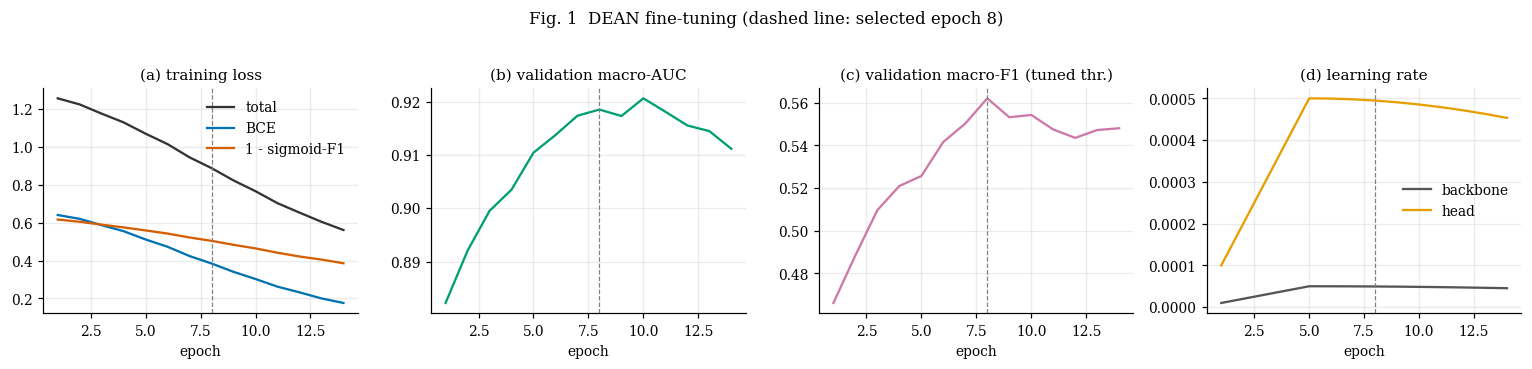

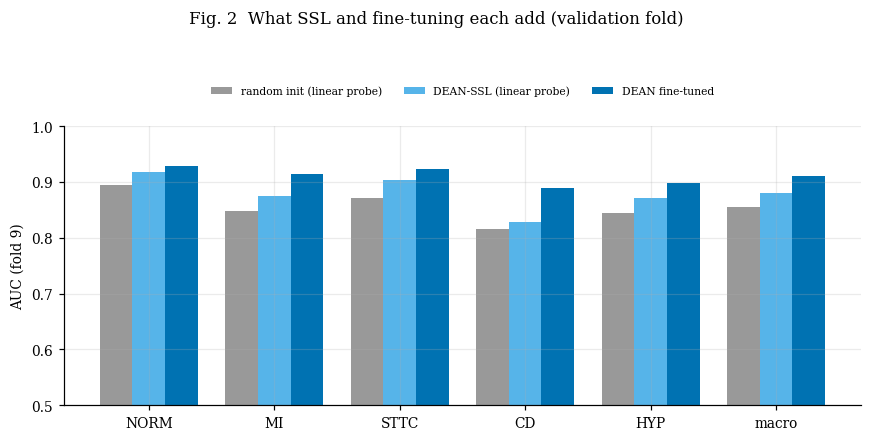

In [13]:
best_ep = result['best_epoch']
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
ax = axes[0]
ax.plot(hist.epoch, hist.loss, color='#333', label='total'); ax.plot(hist.epoch, hist.bce, color='#0072B2', label='BCE')
ax.plot(hist.epoch, hist.f1_loss, color='#D55E00', label='1 - sigmoid-F1'); ax.legend(); ax.set_title('(a) training loss')
axes[1].plot(hist.epoch, hist.val_macro_auc, color='#009E73'); axes[1].set_title('(b) validation macro-AUC')
axes[2].plot(hist.epoch, hist.val_macro_f1, color='#CC79A7'); axes[2].set_title('(c) validation macro-F1 (tuned thr.)')
axes[3].plot(hist.epoch, hist.lr_backbone, label='backbone', color='#555'); axes[3].plot(hist.epoch, hist.lr_head, label='head', color='#E69F00')
axes[3].set_title('(d) learning rate'); axes[3].legend()
for a in axes:
    a.set_xlabel('epoch'); a.axvline(best_ep, ls='--', color='gray', lw=0.8)
fig.suptitle(f'Fig. 1  DEAN fine-tuning (dashed line: selected epoch {best_ep})', y=1.03)
fig.tight_layout()
save_fig(fig, 'fig01_finetune_curves')

# probe vs fine-tune
methods = [('random init (linear probe)', '#999999'), ('DEAN-SSL (linear probe)', '#56B4E9'), ('DEAN fine-tuned', '#0072B2')]
fig, ax = plt.subplots(figsize=(8, 3.8))
w = 0.26
auc_by = {'random init (linear probe)': auc_per_label(Yva, PROBE['random init']['S'], 1),
          'DEAN-SSL (linear probe)': auc_per_label(Yva, PROBE['DEAN-SSL']['S'], 1), 'DEAN fine-tuned': auc_per_label(Yva, S_ft, 1)}
for i, (nm, colr) in enumerate(methods):
    vals = list(auc_by[nm][:5]) + [BOOT[nm]['super_auc'][0]]
    ax.bar(np.arange(6) + (i - 1) * w, vals, w, label=nm, color=colr)
ax.set_xticks(range(6)); ax.set_xticklabels(SUPER + ['macro']); ax.set_ylim(0.5, 1.0); ax.set_ylabel('AUC (fold 9)')
ax.legend(fontsize=7, ncol=3, loc='upper center', bbox_to_anchor=(0.5, 1.18))
fig.suptitle('Fig. 2  What SSL and fine-tuning each add (validation fold)', y=1.04)
fig.tight_layout()
save_fig(fig, 'fig02_probe_vs_finetune')

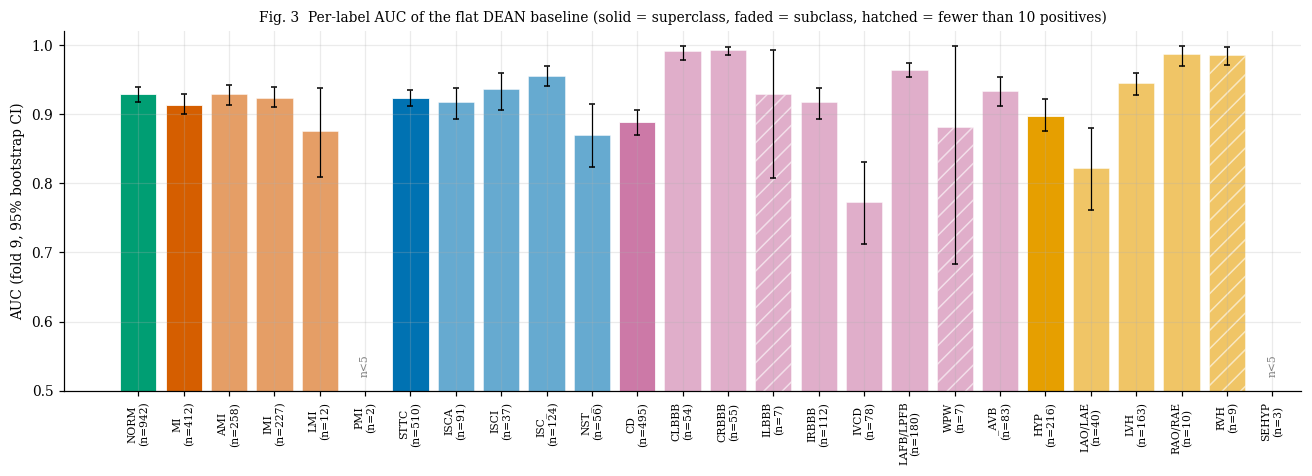

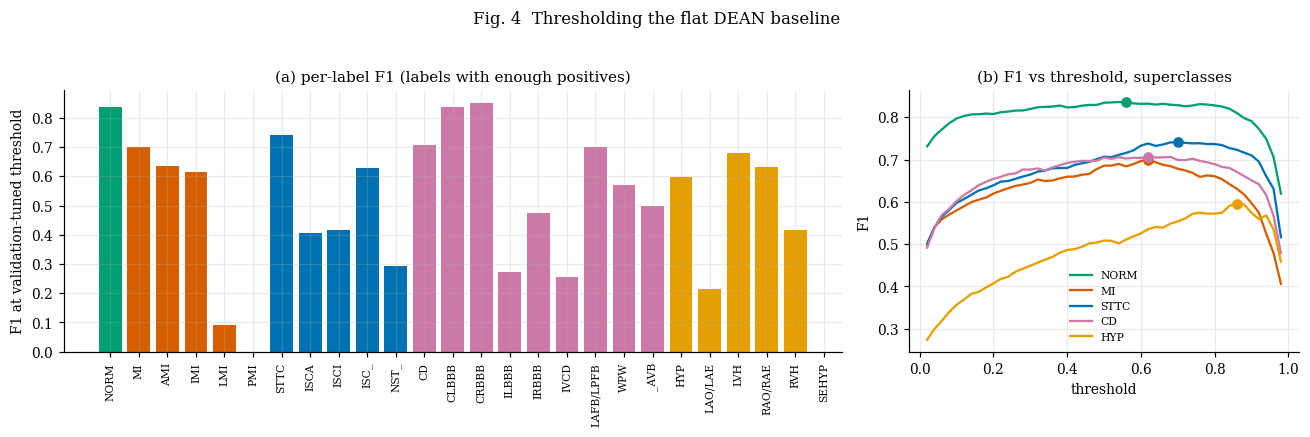

In [14]:
# per-label AUC with bootstrap intervals, grouped by family
order = [l for s in SUPER for l in [s] + [x for x in SUB if FAMILY[x] == s]]
idx = [LABELS.index(l) for l in order]
fig, ax = plt.subplots(figsize=(12, 4.4))
for k, j in enumerate(idx):
    lab = LABELS[j]
    fam = lab if lab in SUPER else FAMILY[lab]
    a, lo, hi = PL.auc[j], PL.auc_lo[j], PL.auc_hi[j]
    if not np.isfinite(a) or PL.n_pos[j] < CFG['min_pos_report']:
        ax.text(k, 0.52, 'n<%d' % CFG['min_pos_report'], rotation=90, ha='center', va='bottom', fontsize=7, color='gray')
        continue
    ax.bar(k, a, color=SUPER_COL[fam], alpha=1.0 if lab in SUPER else 0.6, hatch='//' if PL.n_pos[j] < CFG['min_pos_select'] else None,
           edgecolor='white', lw=0.5)
    ax.errorbar(k, a, yerr=[[a - lo], [hi - a]], color='k', lw=0.8, capsize=2)
ax.set_xticks(range(len(idx))); ax.set_xticklabels([f'{LABELS[j]}\n(n={int(PL.n_pos[j])})' for j in idx], rotation=90, fontsize=7)
ax.set_ylim(0.5, 1.02); ax.set_ylabel('AUC (fold 9, 95% bootstrap CI)'); ax.axhline(0.5, color='k', lw=0.6)
ax.set_title('Fig. 3  Per-label AUC of the flat DEAN baseline (solid = superclass, faded = subclass, hatched = fewer than %d positives)' % CFG['min_pos_select'], fontsize=9)
fig.tight_layout()
save_fig(fig, 'fig03_per_label_auc')

# per-label F1 and threshold
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={'width_ratios': [2, 1]})
ok = PL.reliable.values
axes[0].bar(range(len(idx)), [PL.f1[j] if ok[j] else np.nan for j in idx], color=[SUPER_COL[LABELS[j] if LABELS[j] in SUPER else FAMILY[LABELS[j]]] for j in idx])
axes[0].set_xticks(range(len(idx))); axes[0].set_xticklabels([LABELS[j] for j in idx], rotation=90, fontsize=7)
axes[0].set_ylabel('F1 at validation-tuned threshold'); axes[0].set_title('(a) per-label F1 (labels with enough positives)')
for g, s in enumerate(SUPER):
    j = LABELS.index(s)
    grid = eval_lib.THR_GRID
    f = [f1_at(Yva[:, j:j + 1], S_ft[:, j:j + 1], [t])[0] for t in grid]
    axes[1].plot(grid, f, color=SUPER_COL[s], label=s)
    axes[1].plot(THR[j], PL.f1[j], 'o', color=SUPER_COL[s])
axes[1].set_xlabel('threshold'); axes[1].set_ylabel('F1'); axes[1].legend(fontsize=7); axes[1].set_title('(b) F1 vs threshold, superclasses')
fig.suptitle('Fig. 4  Thresholding the flat DEAN baseline', y=1.03)
fig.tight_layout()
save_fig(fig, 'fig04_f1_and_thresholds')

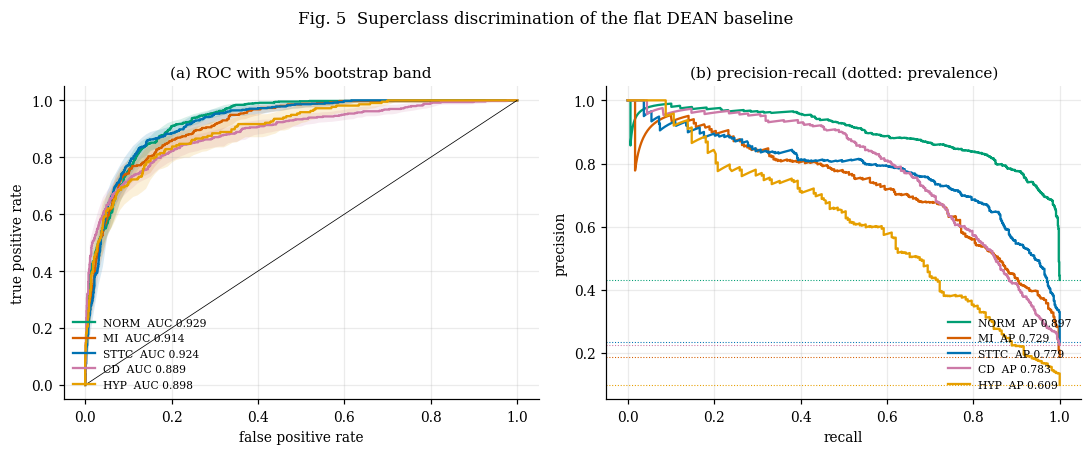

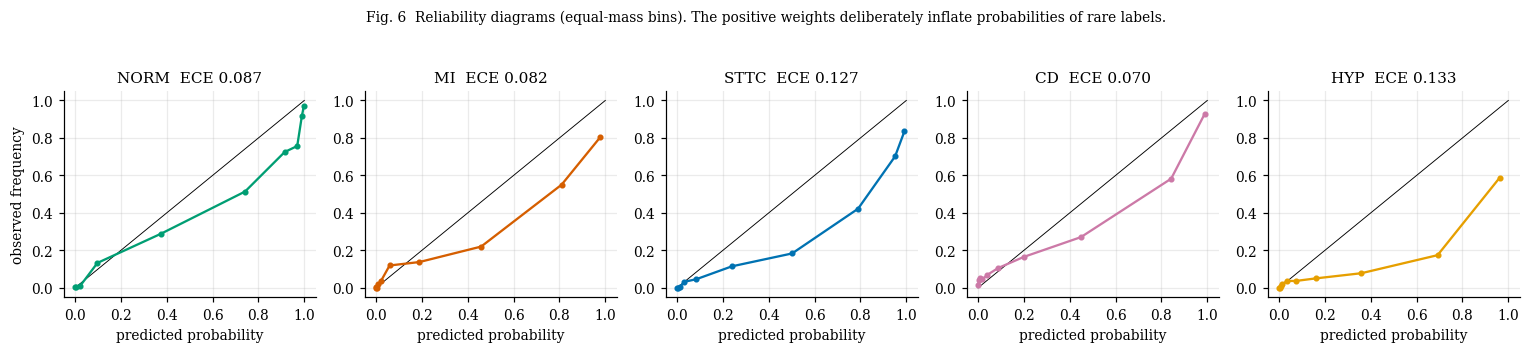

ECE: {'NORM': 0.087, 'MI': 0.082, 'STTC': 0.127, 'CD': 0.07, 'HYP': 0.133}


In [15]:
# ROC (with bootstrap band) and precision-recall for the superclasses
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score
fpr_grid = np.linspace(0, 1, 101)
rng = np.random.default_rng(1)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for s in SUPER:
    j = LABELS.index(s)
    f, t, _ = roc_curve(Yva[:, j], S_ft[:, j])
    tp_boot = []
    for _ in range(150):
        ii = rng.integers(0, len(Yva), len(Yva))
        if Yva[ii, j].sum() in (0, len(ii)):
            continue
        fb, tb, _ = roc_curve(Yva[ii, j], S_ft[ii, j])
        tp_boot.append(np.interp(fpr_grid, fb, tb))
    lo, hi = np.percentile(tp_boot, [2.5, 97.5], axis=0)
    axes[0].plot(f, t, color=SUPER_COL[s], label=f'{s}  AUC {PL.auc[j]:.3f}')
    axes[0].fill_between(fpr_grid, lo, hi, color=SUPER_COL[s], alpha=0.15, lw=0)
    p, r, _ = precision_recall_curve(Yva[:, j], S_ft[:, j])
    axes[1].plot(r, p, color=SUPER_COL[s], label=f'{s}  AP {PL.ap[j]:.3f}')
    axes[1].axhline(Yva[:, j].mean(), color=SUPER_COL[s], ls=':', lw=0.7)
axes[0].plot([0, 1], [0, 1], color='k', lw=0.5)
axes[0].set_xlabel('false positive rate'); axes[0].set_ylabel('true positive rate'); axes[0].set_title('(a) ROC with 95% bootstrap band')
axes[1].set_xlabel('recall'); axes[1].set_ylabel('precision'); axes[1].set_title('(b) precision-recall (dotted: prevalence)')
for a in axes: a.legend(fontsize=7, loc='lower left' if a is axes[0] else 'lower right')
fig.suptitle('Fig. 5  Superclass discrimination of the flat DEAN baseline', y=1.02)
fig.tight_layout()
save_fig(fig, 'fig05_roc_pr_superclass')

# calibration
fig, axes = plt.subplots(1, 5, figsize=(14, 3))
ece_all = {}
for ax, s in zip(axes, SUPER):
    j = LABELS.index(s)
    conf, accu, e = reliability(Yva[:, j], S_ft[:, j], bins=10)
    ece_all[s] = e
    ax.plot([0, 1], [0, 1], color='k', lw=0.6); ax.plot(conf, accu, 'o-', color=SUPER_COL[s], ms=3)
    ax.set_title(f'{s}  ECE {e:.3f}'); ax.set_xlabel('predicted probability')
axes[0].set_ylabel('observed frequency')
fig.suptitle('Fig. 6  Reliability diagrams (equal-mass bins). The positive weights deliberately inflate probabilities of rare labels.', y=1.05, fontsize=9)
fig.tight_layout()
save_fig(fig, 'fig06_calibration')
print('ECE:', {k: round(v, 3) for k, v in ece_all.items()})

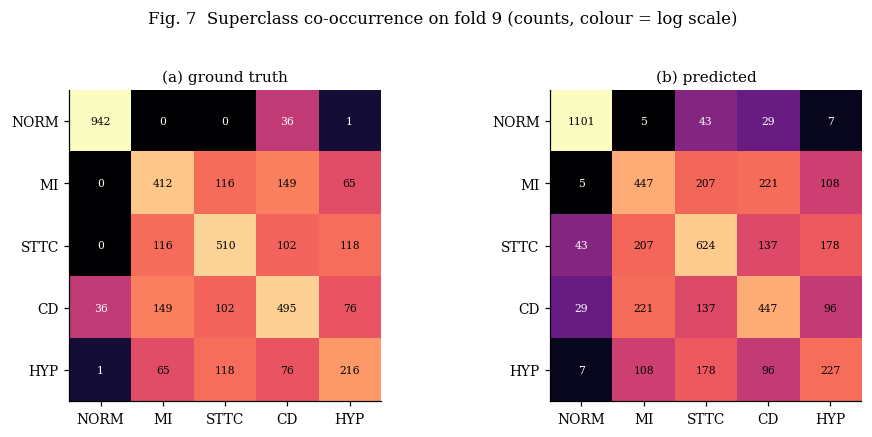

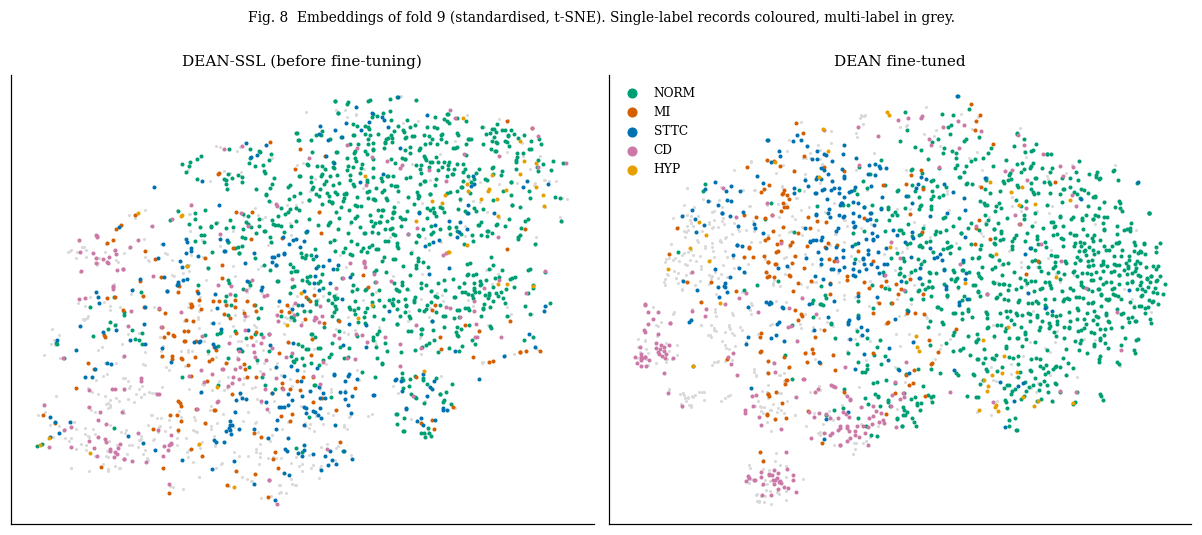

In [16]:
# co-occurrence of superclasses: truth vs prediction, and t-SNE before / after fine-tuning
pred_sup = (S_ft[:, :5] >= THR[:5][None]).astype(float)
co_true, co_pred = Yva[:, :5].T @ Yva[:, :5], pred_sup.T @ pred_sup
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, M, ttl in [(axes[0], co_true, '(a) ground truth'), (axes[1], co_pred, '(b) predicted')]:
    im = ax.imshow(np.log1p(M), cmap='magma'); ax.grid(False)
    for a_ in range(5):
        for b_ in range(5):
            ax.text(b_, a_, int(M[a_, b_]), ha='center', va='center', fontsize=7, color='w' if np.log1p(M[a_, b_]) < 0.6 * np.log1p(M.max()) else 'k')
    ax.set_xticks(range(5)); ax.set_xticklabels(SUPER); ax.set_yticks(range(5)); ax.set_yticklabels(SUPER); ax.set_title(ttl)
fig.suptitle('Fig. 7  Superclass co-occurrence on fold 9 (counts, colour = log scale)', y=1.03)
fig.tight_layout()
save_fig(fig, 'fig07_cooccurrence')

from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
sup_n = Yva[:, :5].sum(1)
prim = Yva[:, :5].argmax(1)
single = np.where(sup_n == 1)[0]
def tsne_xy(Zn):
    Zn = (Zn - Zn.mean(0)) / (Zn.std(0) + 1e-6)
    k = min(50, Zn.shape[1], Zn.shape[0] - 1)
    Zp = PCA(n_components=k, random_state=0).fit_transform(Zn)
    return TSNE(n_components=2, perplexity=min(30, len(Zn) // 4), init='pca', learning_rate='auto', random_state=0).fit_transform(Zp)
XY = {'DEAN-SSL (before fine-tuning)': tsne_xy(Z['DEAN-SSL'][1].cpu().numpy()), 'DEAN fine-tuned': tsne_xy(emb_va)}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, (nm, xy) in zip(axes, XY.items()):
    ax.scatter(xy[:, 0], xy[:, 1], s=4, c='#d9d9d9', lw=0)
    for j, s in enumerate(SUPER):
        ii = single[prim[single] == j]
        ax.scatter(xy[ii, 0], xy[ii, 1], s=7, color=SUPER_COL[s], lw=0, label=s)
    ax.set_title(nm); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
axes[1].legend(markerscale=2.5, fontsize=8)
fig.suptitle('Fig. 8  Embeddings of fold 9 (standardised, t-SNE). Single-label records coloured, multi-label in grey.', y=1.0, fontsize=9)
fig.tight_layout()
save_fig(fig, 'fig08_tsne_before_after')

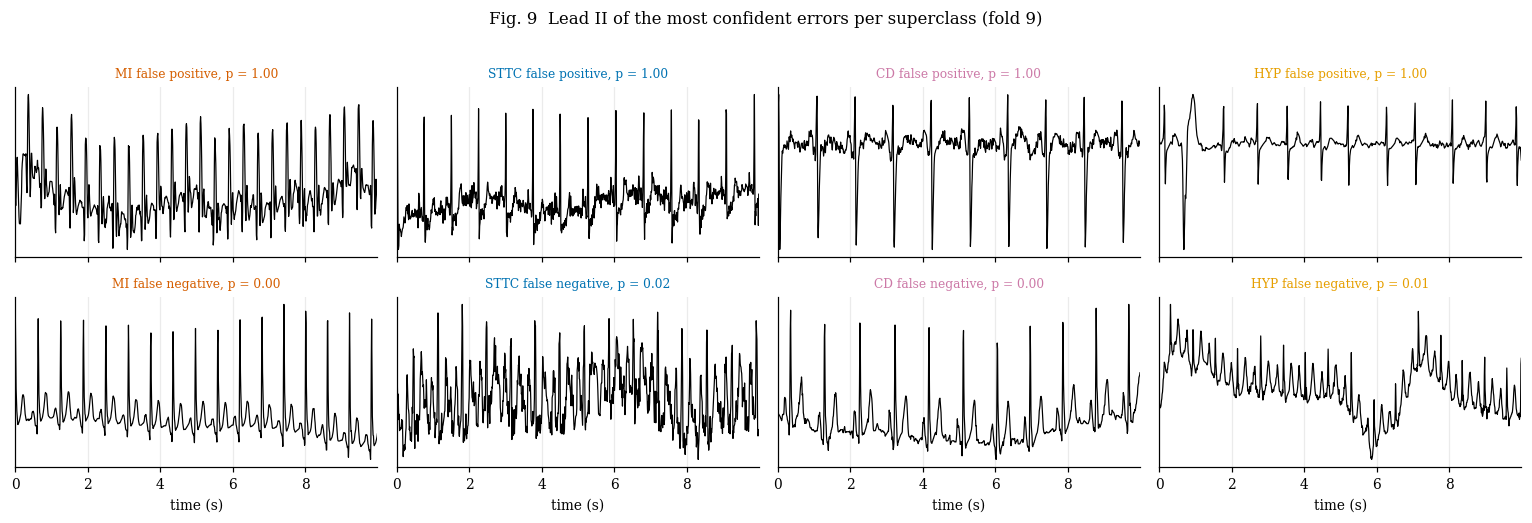

In [17]:
# most confident mistakes, as a sanity check that the model fails for understandable reasons
Xva_np = DATA['X_va'].cpu().numpy()
show = ['MI', 'STTC', 'CD', 'HYP']
fig, axes = plt.subplots(2, 4, figsize=(14, 4.6), sharex=True)
t = np.arange(Xva_np.shape[2]) / 100
for c_, s in enumerate(show):
    j = LABELS.index(s)
    neg, pos = np.where(Yva[:, j] == 0)[0], np.where(Yva[:, j] == 1)[0]
    fp_i = neg[np.argmax(S_ft[neg, j])]
    fn_i = pos[np.argmin(S_ft[pos, j])]
    for r_, (i_, kind) in enumerate([(fp_i, 'false positive'), (fn_i, 'false negative')]):
        ax = axes[r_, c_]
        ax.plot(t, Xva_np[i_, 1] * SD[1] + MU[1], color='k', lw=0.8)
        ax.set_title(f'{s} {kind}, p = {S_ft[i_, j]:.2f}', fontsize=8, color=SUPER_COL[s])
        ax.set_yticks([]); ax.margins(x=0)
for ax in axes[-1]: ax.set_xlabel('time (s)')
fig.suptitle('Fig. 9  Lead II of the most confident errors per superclass (fold 9)', y=1.02)
fig.tight_layout()
save_fig(fig, 'fig09_error_examples')

## 12. Export and teacher cache
DEAN is frozen from here on. The cache holds, for the training and validation records in the original row order of `split_idx.npz`: the 26-d logits, the pooled 256-d embeddings and the final-layer token sequences (40 x 256, float16). In NB-05 the token sequences are the `y_t` that the Gram-RKD term compares against. Logits on the training set come from a model that was fitted on those same records, so they are more confident than they would be on new data; the distillation notebooks use a temperature for that reason.

In [18]:
t0 = time.time()
lg_tr, em_tr, tk_tr = predict(model, DATA['X_tr'], tokens=True)
lg_va, em_va, tk_va = predict(model, DATA['X_va'], tokens=True)
print(f'cache built in {time.time() - t0:.0f}s | tokens {tk_tr.shape} {tk_tr.dtype}')
assert np.isfinite(lg_tr).all() and np.isfinite(tk_tr.astype(np.float32)).all()
assert np.allclose(lg_va, logits_va, atol=1e-3), 'cached validation logits differ from the evaluated ones'

for nm, arr in [('dean_logits_train', lg_tr), ('dean_logits_val', lg_va), ('dean_emb_train', em_tr), ('dean_emb_val', em_va),
                ('dean_tokens_train_fp16', tk_tr), ('dean_tokens_val_fp16', tk_va)]:
    np.save(os.path.join(WORK, nm + '.npy'), arr)
np.savez(os.path.join(WORK, 'split_idx.npz'), train_idx=tr_idx, val_idx=va_idx, test_idx=te_idx,
         ecg_id_train=ecg_id[tr_idx], ecg_id_val=ecg_id[va_idx], label_columns=np.array(LABELS))

torch.save({
    'encoder': model.enc.state_dict(), 'head': model.head.state_dict(), 'enc_config': ENC_CFG,
    'label_columns': LABELS, 'thresholds': THR.tolist(), 'norm_mean': MU.tolist(), 'norm_std': SD.tolist(),
    'best_epoch': int(result['best_epoch']), 'ssl_source': ssl_path,
}, os.path.join(WORK, 'dean_finetuned.pt'))

metrics = {
    'note': 'validation fold only (fold 9). Thresholds were tuned on this fold, so F1 is optimistic. Test numbers come from NB-09.',
    'best_epoch': int(result['best_epoch']), 'epochs_run': int(len(hist)),
    'encoder_params_M': count_params(model.enc) / 1e6, 'head_params_K': count_params(model.head) / 1e3,
    'min_pos_report': CFG['min_pos_report'],
    'bootstrap_95ci': {nm: {k: v for k, v in b.items() if not k.startswith('label_')} for nm, b in BOOT.items()},
    'probe_auc': probe_tab.to_dict(), 'ece_superclass': ece_all,
    'per_label': PL.round(4).to_dict(orient='records'),
}
json.dump(metrics, open(os.path.join(WORK, 'baseline_metrics.json'), 'w'), indent=2)
json.dump({'CFG': CFG, 'ENC_CFG': ENC_CFG, 'versions': VERSIONS, 'scan': 'unbind' if dean_lib.selective_scan is fast_scan else 'library',
           'labels': LABELS, 'train_folds': [1, 2, 3, 4, 5, 6, 7, 8], 'val_fold': 9}, open(os.path.join(WORK, 'dean_ft_config.json'), 'w'), indent=2)

shutil.rmtree(os.path.join(WORK, 'smoke_tmp'), ignore_errors=True)
print('files in /kaggle/working:')
for root, _, files in os.walk(WORK):
    for f in sorted(files):
        p = os.path.join(root, f)
        if '__pycache__' in p or p.endswith('.tmp'):
            continue
        print(f'  {os.path.relpath(p, WORK):45s} {os.path.getsize(p) / 1e6:8.2f} MB')

cache built in 37s | tokens (17418, 40, 256) float16
files in /kaggle/working:
  __notebook__.ipynb                                1.14 MB
  baseline_metrics.json                             0.01 MB
  dean_emb_train.npy                               17.84 MB
  dean_emb_val.npy                                  2.24 MB
  dean_finetuned.pt                                46.05 MB
  dean_ft_config.json                               0.00 MB
  dean_lib.py                                       0.01 MB
  dean_logits_train.npy                             1.81 MB
  dean_logits_val.npy                               0.23 MB
  dean_tokens_train_fp16.npy                      356.72 MB
  dean_tokens_val_fp16.npy                         44.71 MB
  eval_lib.py                                       0.00 MB
  ft_history.csv                                    0.00 MB
  probe_results.csv                                 0.00 MB
  split_idx.npz                                     0.33 MB
  val_metrics_table.c

## 13. After this notebook
1. Save a version, then create the Dataset **`dean-finetuned-v1`** from the output. The important files are `dean_finetuned.pt`, `baseline_metrics.json`, `eval_lib.py`, `dean_lib.py`, `split_idx.npz` and the six cache arrays. `ckpt/` is only needed if the run paused.
2. The number every later tier has to beat is the fine-tuned row of `val_metrics_table.csv`. Do not quote its F1 as a test result.
3. NB-03 (gating) reads `dean_emb_*.npy` and `split_idx.npz`, so it needs no GPU time for the encoder. Embedding dimension is 256, so the gate MLP has about 67K parameters, as recorded in the project notes.
4. If a better SSL encoder comes out of a later NB-01 run, attach it, re-run this notebook unchanged and compare the two `baseline_metrics.json` files. That comparison is a ready-made ablation.